# Tukey: learning to explore data with verifiable rewards

- This notebook shows the project's results: synthetic causal worlds with a
  known answer and a statistical toolbox with a scripted baseline (this
  version); the trained policy and its generalization tests come with the next
  PRs
- The pedagogical arc:
  - Part 1: the synthetic environment and what its data leak (Milestone 1)
  - Part 2: the toolbox, the scripted agent and the baseline table
    (Milestone 2)
- This version covers Milestones 1-2; the trained policy (Milestone 3) and
  generalization and real data (Milestone 4) arrive with the next PRs

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook
import tukey_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpcclj0ytt.json --HistoryManager.hist_file=:memory:


# Part 1: The synthetic environment

## Cell 1.1: Pinned scientific stack

**Goal**
- Confirm the container runs the pinned versions the results were produced
  with

In [3]:
# Report the version of every package the project depends on.
versions = utils.cell1_1_get_package_versions()
display(versions)
# Outcome: one row per core package, each at the version pinned in
# `requirements.txt`.

,package,version
0,numpy,2.5.4
1,pandas,3.0.6
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,networkx,3.7
5,causal-learn,0.1.4.8
6,lingam,1.12.2
7,CausalDisco,0.2.4
8,pgmpy,1.1.2


## Cell 1.2: A gallery of hidden graphs

**Goal**
- See the graph shapes the generator draws and the target each one sets

**Description**
- One panel per topology (Erdos-Renyi, scale-free hubs, star, layered), each
  with its identifiable target class (DAG or CPDAG, by the noise drawn); the
  generator also draws chains

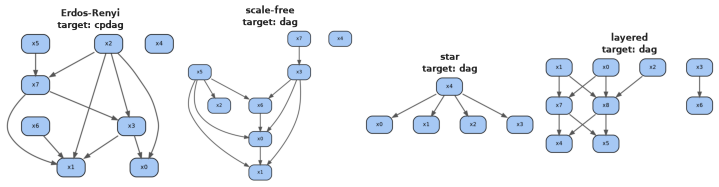

In [4]:
# Draw one hidden graph per topology.
utils.example_cell1_2_plot_gallery(seed=0)

**Implementation** `example_cell1_2_plot_gallery()`
- Samples one instance per topology and plots its graph with
  `plot_causal_dag()`

In [5]:
hintros.print_obj_info(utils.example_cell1_2_plot_gallery)

- `example_cell1_2_plot_gallery(*, seed: int = 0, figsize: Tuple[float, float] = (14.0, 3.5)) -> None`  
  Plot one hidden graph per topology, with its identifiable target.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_utils.py#L284


## Cell 1.3: What simulated data leak about the causal order

**Goal**
- Measure how far simple scores (variance, R^2, number of relatives) reveal
  the causal order, before any agent is trained

**Description**
- `var_raw`, `var_std`: sortability by variance on raw and standardized data
- `r2`, `rel_oracle`, `rel_empirical`: sortability by R^2 and by the number
  of relatives (true graph, or significant correlations)
- `var_sort_minus_random_shd`: SHD of var-sort-regress minus random-order
  regress on standardized data, with its Holm-adjusted p-value

In [6]:
# Load the committed report (100 validation graphs per family).
sortability = utils.example_cell1_3_load_sortability()
display(sortability)

,family,var_raw,var_std,r2,rel_oracle,rel_empirical,var_sort_minus_random_shd,holm_p
0,eqvar_raw,0.912,0.5,0.598,0.735,0.710,0.71,1.000
1,iscm,0.488,0.5,0.467,0.757,0.732,-0.45,1.000
2,linear_exp,0.880,0.5,0.565,0.745,0.728,0.33,1.000
3,linear_gauss,0.901,0.5,0.535,0.742,0.719,-1.13,0.273
4,linear_uniform,0.870,0.5,0.553,0.743,0.708,-1.07,0.467
5,mixed,0.868,0.5,0.533,0.749,0.723,-1.06,1.000
6,mixed_d10,0.881,0.5,0.549,0.774,0.743,-0.30,1.000
7,mixed_d15,0.873,0.5,0.542,0.820,0.780,0.19,1.000
8,mixed_node,0.874,0.5,0.563,0.746,0.722,0.07,1.000
9,nonlinear,0.829,0.5,0.705,0.745,0.735,0.18,1.000


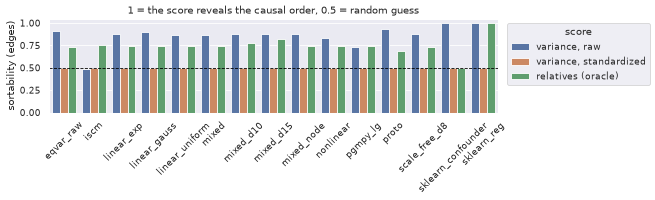

In [7]:
# Plot variance and relatives sortability per family.
utils.example_cell1_3_plot_sortability(sortability)

**Guided usage**
- Compare the blue and orange bars: standardizing removes the variance leak
  (0.5 everywhere) while the prototype's raw data stay at 0.94
- Look at the green bars: the number of relatives stays above 0.5 (0.67 to
  1.00) in every random-graph family, including iSCM data, because it depends
  on the graph, not on the weights; the exception is `sklearn_confounder`
  (0.50 with the true graph, 0.49 estimated: no order signal)

**Implementation** `example_cell1_3_load_sortability()`
- Reads `results/m1/sortability.json` (written by
  `tukey_results.py sortability`); the edge
  definition (Reisach et al. 2026, Eq. 4) counts each edge once, ties 1/2

In [8]:
hintros.print_obj_info(utils.example_cell1_3_load_sortability)

- `example_cell1_3_load_sortability(path: str = 'results/m1/sortability.json') -> pandas.DataFrame`  
  Load the M1 sortability report as one row per family.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_utils.py#L315


# Part 2: The toolbox, the scripted agent and the baselines

## Cell 2.1: The baseline table on the main task

**Goal**
- Rank every non-learned method on the main task distribution (setting `D`:
  6-8 variables, one noise family per graph, standardized)

**Description**
- `score`: mean combined score over 200 benchmark graphs and its bootstrap
  95% interval; `shd_target`: distance to the identifiable target;
  `exact_recovery`: share of graphs recovered exactly; `calls`: tool calls
  (scripted agents) or distinct CI tests (PC; corrected after the audit, the
  stored counts include 3 cache entries, `results/post_audit/`)

In [9]:
# Methods tuned on the validation twin of the setting, scored once here.
display(utils.example_cell2_1_load_m2_table("D"))
# Outcome: GES, DirectLiNGAM and sort-by-relatives lead; the prototype's rule
# (`proto_scripted`) is below the classical methods; this is the baseline the
# learned policy must beat.

,method,score,score_ci,shd_target,exact_recovery,calls
0,ges,-0.196,"[-0.224, -0.169]",3.525,0.250,0.000
1,direct_lingam,-0.242,"[-0.290, -0.195]",4.275,0.595,0.000
2,rel_sort_regress_tuned,-0.260,"[-0.290, -0.230]",4.655,0.155,0.000
3,rel_sort_regress,-0.262,"[-0.293, -0.232]",4.690,0.140,0.000
4,pc_tuned,-0.292,"[-0.319, -0.266]",4.190,0.080,170.005
5,pc,-0.295,"[-0.324, -0.268]",4.155,0.075,159.700
6,scripted_plus,-0.350,"[-0.374, -0.325]",4.420,0.020,156.420
7,scripted_tuned,-0.406,"[-0.431, -0.381]",6.240,0.015,90.825
8,proto_scripted,-0.416,"[-0.440, -0.392]",5.990,0.020,76.555
9,random_sort_regress,-0.547,"[-0.585, -0.508]",9.810,0.030,0.000


## Cell 2.2: Every method with a combined score, in every setting

**Goal**
- See where each method's assumptions hold

**Description**
- One column per setting (`A0` prototype data, `A1` exponential, `B` Gaussian,
  `Braw` equal-variance raw, `C` uniform, `D` main task, `E` nonlinear, `F`
  observed confounder, `G` pgmpy, `H` 12 variables); one row per method

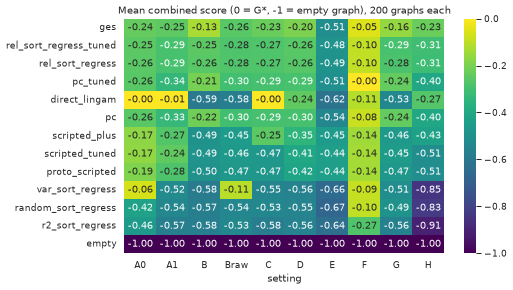

In [10]:
# Mean combined score, 200 graphs per cell.
utils.example_cell2_2_plot_m2_heatmap()

**Guided usage**
- Read the `direct_lingam` row: near 0 on non-Gaussian data (`A0`, `A1`, `C`),
  poor on Gaussian data (`B`, `Braw`)
- Read the `var_sort_regress` row: strong where variance is a real or leaked
  signal (`A0` raw prototype data, `Braw` equal variances); setting `F` is
  easy for every method (a random order scores -0.095 there)
- Read the `ges` and `pc` rows: best on Gaussian data, where the target is the
  equivalence class

**Implementation** `example_cell2_2_plot_m2_heatmap()`
- Reads `results/m2/table_summary.json` (written by `tukey_results.py
  m2_table` and `m2_split`)

In [11]:
hintros.print_obj_info(utils.example_cell2_2_plot_m2_heatmap)

- `example_cell2_2_plot_m2_heatmap(path: str = 'results/m2/table_summary.json', *, figsize: Tuple[float, float] = (9.0, 5.0)) -> None`  
  Plot the mean combined score of every method with a combined score, in...

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_utils.py#L465
